In [3]:
# Simple Linear Regression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

In [5]:
df = fetch_california_housing(as_frame = True).frame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [ ]:
# target variable --> MedHouseVal

In [6]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [7]:
df.isnull().sum()  # no null values

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [10]:
df.duplicated().sum()  # no duplicates 

np.int64(0)

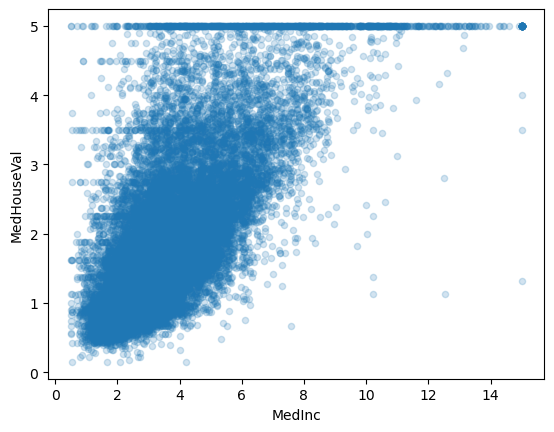

In [13]:
df.plot.scatter(x = "MedInc", y = "MedHouseVal", alpha = 0.2)  # alpha controls transparancy (0 to 1)
plt.show()

# relationship is roughly linear and house values are capped at 5.

In [18]:
# model is y = b0 + b1.x

x = df['MedInc'].values  # numpy array
y = df['MedHouseVal'].values  # numpy array

b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
b0 = y.mean() - b1 * x.mean()

print(b0 , b1)

0.4508557670326805 0.4179384920189625


In [19]:
y_pred = b0 + b1 * x
rmse = np.sqrt(np.mean((y - y_pred) ** 2))
r2 = 1 - np.sum((y - y_pred) ** 2) / np.sum((y - y.mean()) ** 2)
print(rmse, r2)

0.8373357452616917 0.4734474918071989


In [21]:
# using gradient descent

w, b, lr = 0.0, 0.0, 0.01

for _ in range(5000):
    err = (w * x + b) - y
    w -= lr * 2 * np.mean(err * x)
    b -= lr * 2 * np.mean(err)
print(b, w)  # should be close to b0, b1

0.450855764223094 0.4179384926098255


lr=0.1: w=-29279622152938656744717062050821102077841243621288085079985632758122417621079885972563606809753705846586317802378412203102826126274393796532925194658912516017691911072042142453251393998004768497335800174639022523038251182043693056.0000, b=-6157578012968060961042660740954886477408746306540642016010975217646582924762138439936534222989477995982657954086118627066241569050651902898928693957048275560466023003829098561497937531310247805196215990276439080044173551411920896.0000, final loss=inf
lr=0.01: w=0.4293, b=0.3969, final loss=0.7017
lr=0.001: w=0.4786, b=0.1623, final loss=0.7173


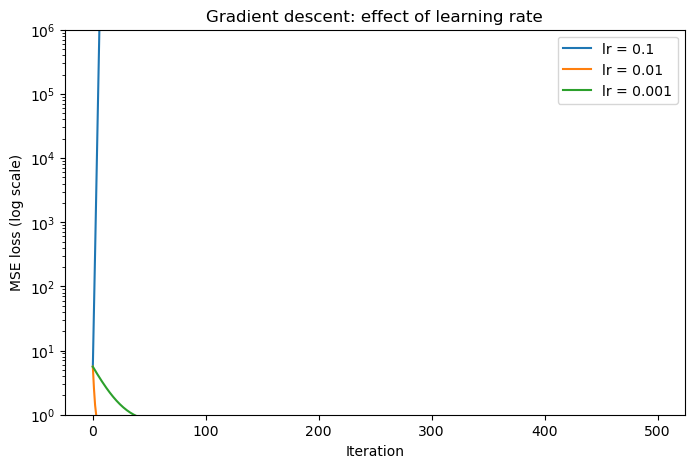

In [24]:
import numpy as np
import matplotlib.pyplot as plt

def gradient_descent(x, y, lr, n_iters=500):
    w, b = 0.0, 0.0
    losses = []
    for _ in range(n_iters):
        err = (w * x + b) - y
        losses.append(np.mean(err ** 2))      # record loss BEFORE the update
        w -= lr * 2 * np.mean(err * x)
        b -= lr * 2 * np.mean(err)
    return w, b, losses

learning_rates = [ 0.1, 0.01, 0.001]

fig, ax = plt.subplots(figsize=(8, 5))
for lr in learning_rates:
    with np.errstate(all="ignore"):           # silence overflow warnings when it diverges
        w, b, losses = gradient_descent(x, y, lr)
    ax.plot(losses, label=f"lr = {lr}")
    print(f"lr={lr}: w={w:.4f}, b={b:.4f}, final loss={losses[-1]:.4f}")

ax.set_yscale("log")                          # makes divergence and slow convergence both visible
ax.set_ylim(top=1e6)                          # stops the diverging run from squashing the other lines
ax.set_xlabel("Iteration")
ax.set_ylabel("MSE loss (log scale)")
ax.set_title("Gradient descent: effect of learning rate")
ax.legend()
plt.show()

In [25]:
# verify with scikit learn

from sklearn.linear_model import LinearRegression
m = LinearRegression().fit(x.reshape(-1,1), y)
print(m.intercept_, m.coef_)

0.4508557670326794 [0.41793849]


In [28]:
# Simple linear regression

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [29]:
target = 'MedHouseVal'
x = df[['MedInc']]
y = df[target]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.2, random_state = 42
)

In [30]:
model = LinearRegression()
model.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [35]:
print(f'intercept (b0) : {model.intercept_:.4f}')
print(f'slope (b1) : {model.coef_[0]:.4f}')
print()
print("-> each +1 unit of MedInc (~$10k) is associated with a "
      f"{model.coef_[0]:.2f} unit change in MedHouseVal (~${model.coef_[0]*100:.0f}k)")

intercept (b0) : 0.4446
slope (b1) : 0.4193

-> each +1 unit of MedInc (~$10k) is associated with a 0.42 unit change in MedHouseVal (~$42k)


In [ ]:
# for every 1-unit increase in MedInc, the estimated mean (or expected value) of MedHouseVal increases by 0.4193 units.

# for intercept
#  if a neighborhood had a median income of $0 (MedInc = 0), the model predicts the baseline median house value would be about $44,460 (0.4446 × $100,000).

In [37]:
def report(name, y_true, y_pred):
    """Print the standard regression metrics."""
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<8} RMSE={rmse:.4f}  MAE={mae:.4f}  R2={r2:.4f}")

In [39]:
report('train', y_train, model.predict(x_train))
report('train', y_test, model.predict(x_test))

train    RMSE=0.8361  MAE=0.6250  R2=0.4770
train    RMSE=0.8421  MAE=0.6299  R2=0.4589


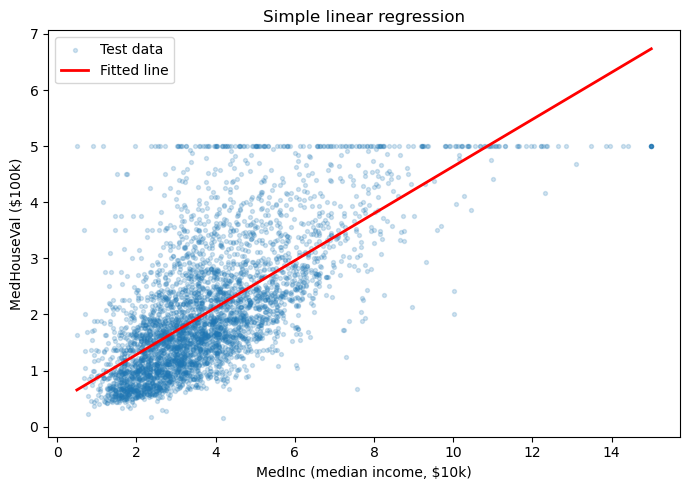

In [42]:
x_line = np.linspace(x["MedInc"].min(), x["MedInc"].max(), 100).reshape(-1, 1)
x_line = pd.DataFrame(x_line, columns=["MedInc"])
 
plt.figure(figsize=(7, 5))
plt.scatter(x_test, y_test, alpha=0.2, s=8, label="Test data")
plt.plot(x_line, model.predict(x_line), color="red", linewidth=2, label="Fitted line")
plt.xlabel("MedInc (median income, $10k)")
plt.ylabel("MedHouseVal ($100k)")
plt.title("Simple linear regression")
plt.legend()
plt.tight_layout()
plt.show()
 